In [1]:
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt

In [2]:
rfm = pd.read_csv(
    "../data/processed/rfm_customer_segments.csv"
)

In [3]:
rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,1,77183.60,1,1,4,114,Others
1,12347,2,7,4310.00,4,4,4,444,Champions
2,12348,75,4,1797.24,2,3,4,234,At Risk
3,12349,19,1,1757.55,3,1,4,314,Others
4,12350,310,1,334.40,1,1,2,112,Lost Customers


In [4]:
rfm.info()


<class 'pandas.DataFrame'>
RangeIndex: 4338 entries, 0 to 4337
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   CustomerID  4338 non-null   int64  
 1   Recency     4338 non-null   int64  
 2   Frequency   4338 non-null   int64  
 3   Monetary    4338 non-null   float64
 4   R_Score     4338 non-null   int64  
 5   F_Score     4338 non-null   int64  
 6   M_Score     4338 non-null   int64  
 7   RFM_Score   4338 non-null   int64  
 8   Segment     4338 non-null   str    
dtypes: float64(1), int64(7), str(1)
memory usage: 347.4 KB


In [5]:
rfm_ml = rfm[["Recency", "Frequency", "Monetary"]].copy()

In [6]:
rfm_ml.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [7]:
from sklearn.preprocessing import StandardScaler

In [8]:
scaler = StandardScaler()

In [9]:
rfm_scaled = scaler.fit_transform(rfm_ml)

In [10]:
rfm_scaled[:5]

array([[ 2.33457414, -0.4250965 ,  8.36301037],
       [-0.90534032,  0.3544168 ,  0.2516989 ],
       [-0.17535959, -0.03533985, -0.02798783],
       [-0.73534481, -0.4250965 , -0.03240559],
       [ 2.17457836, -0.4250965 , -0.19081155]])

In [11]:
from sklearn.cluster import KMeans

In [12]:
inertia = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42
    )
    
    model.fit(rfm_scaled)
    
    inertia.append(model.inertia_)

In [13]:
inertia

[9356.670424411008,
 5501.487299697768,
 4096.300210662248,
 3119.7898598001493,
 2473.7933635647596,
 2023.6444551556094,
 1798.8600823031454,
 1468.787102184297,
 1333.1096215503485]

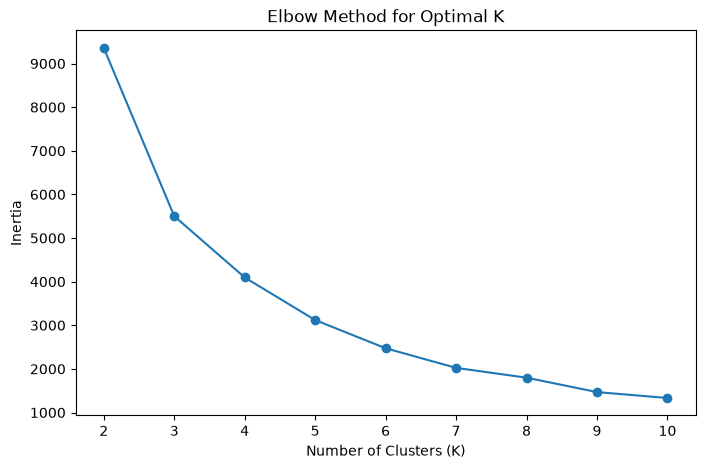

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.show()

In [15]:
from sklearn.metrics import silhouette_score

In [16]:
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42
    )

    labels = model.fit_predict(rfm_scaled)

    score = silhouette_score(rfm_scaled, labels)

    silhouette_scores.append(score)

In [17]:
model.fit(rfm_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](10, 3)",

In [18]:
silhouette_scores

[0.5604013068318398,
 0.5853238625904467,
 0.6162275299061803,
 0.6165002474679848,
 0.5982885618366588,
 0.5170880799084383,
 0.49121068260754397,
 0.4784383467130572,
 0.4448163678156714]

In [19]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

In [20]:
rfm["Cluster"].value_counts().sort_index()

Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64

In [21]:
cluster_profile = rfm.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean()

cluster_profile.round(2)

,Recency,Frequency,Monetary
Cluster,,,
0,43.70,3.68,1353.63
1,248.08,1.55,478.85
2,7.38,82.54,127187.96
3,15.50,22.33,12690.50


In [22]:
cluster_names = {
    0: "Regular Customers",
    1: "Inactive Customers",
    2: "VIP Customers",
    3: "Loyal High-Value Customers"
}

rfm["Cluster_Name"] = rfm["Cluster"].map(cluster_names)

In [23]:
rfm["Cluster_Name"].value_counts()

Cluster_Name
Regular Customers             3054
Inactive Customers            1067
Loyal High-Value Customers     204
VIP Customers                   13
Name: count, dtype: int64

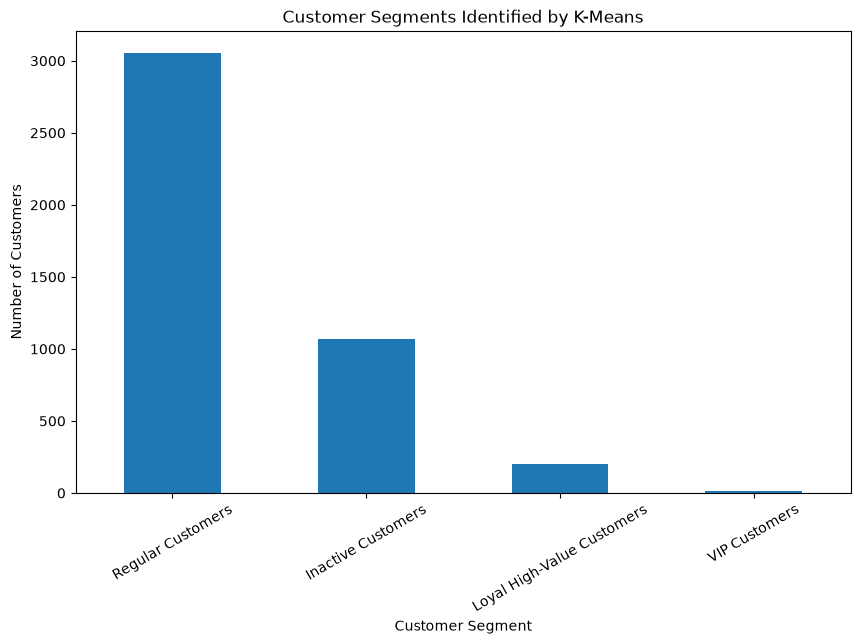

In [24]:
cluster_counts = rfm["Cluster_Name"].value_counts()

plt.figure(figsize=(10, 6))

cluster_counts.plot(kind="bar")

plt.title("Customer Segments Identified by K-Means")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

plt.show()

In [26]:
rfm[rfm["Cluster"] == 2][
    ["CustomerID", "Recency", "Frequency", "Monetary"]
].sort_values("Monetary", ascending=False)

,CustomerID,Recency,Frequency,Monetary
1689,14646,2,73,280206.02
4201,18102,1,60,259657.30
3728,17450,8,46,194390.79
3008,16446,1,2,168472.50
1879,14911,1,201,143711.17
55,12415,24,21,124914.53
1333,14156,10,55,117210.08
3771,17511,3,31,91062.38
2702,16029,39,63,80850.84
2176,15311,1,91,60632.75


In [27]:
import numpy as np

rfm_log = np.log1p(
    rfm[["Recency", "Frequency", "Monetary"]]
)

In [28]:
rfm_log.describe().round(2)

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,3.83,1.35,6.59
std,1.34,0.68,1.26
min,0.69,0.69,1.56
25%,2.94,0.69,5.73
50%,3.95,1.10,6.51
75%,4.96,1.79,7.42
max,5.93,5.35,12.54


In [29]:
from sklearn.preprocessing import StandardScaler

scaler_log = StandardScaler()

rfm_log_scaled = scaler_log.fit_transform(rfm_log)

In [30]:
rfm_log_scaled[:5]

array([[ 1.46199281, -0.95521426,  3.7077163 ],
       [-2.03873442,  1.07442519,  1.41490344],
       [ 0.37310424,  0.38630445,  0.72002428],
       [-0.62308592, -0.95521426,  0.70228691],
       [ 1.42455753, -0.95521426, -0.61451388]])

In [31]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_log = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42)

    labels = model.fit_predict(rfm_log_scaled)

    score = silhouette_score(rfm_log_scaled, labels)

    silhouette_log.append(score)

In [32]:
for k, score in zip(range(2, 11), silhouette_log):
    print(f"K={k}: {score:.3f}")

K=2: 0.433
K=3: 0.336
K=4: 0.335
K=5: 0.314
K=6: 0.315
K=7: 0.296
K=8: 0.277
K=9: 0.281
K=10: 0.277


## Final Model Conclusion

K-Means clustering was applied to Recency, Frequency, and Monetary (RFM)
customer features.

The Elbow Method and Silhouette Score were used to evaluate the optimal
number of clusters.

The original standardized RFM model produced stronger cluster separation
than the log-transformed version.

The final model uses 4 customer clusters:

- Regular Customers
- Inactive Customers
- Loyal High-Value Customers
- VIP Customers

These segments provide actionable insights for customer retention,
reactivation, and targeted marketing strategies.


In [33]:
rfm.to_csv(
    "../data/processed/customer_segments_ml.csv",
    index=False
)

In [34]:
rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Cluster,Cluster_Name
0,12346,326,1,77183.60,1,1,4,114,Others,3,Loyal High-Value Customers
1,12347,2,7,4310.00,4,4,4,444,Champions,0,Regular Customers
2,12348,75,4,1797.24,2,3,4,234,At Risk,0,Regular Customers
3,12349,19,1,1757.55,3,1,4,314,Others,0,Regular Customers
4,12350,310,1,334.40,1,1,2,112,Lost Customers,1,Inactive Customers


In [35]:
rfm.to_csv(
    "../data/processed/customer_segments_ml.csv",
    index=False
)

In [36]:
check_ml = pd.read_csv(
    "../data/processed/customer_segments_ml.csv"
)

check_ml.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Cluster,Cluster_Name
0,12346,326,1,77183.60,1,1,4,114,Others,3,Loyal High-Value Customers
1,12347,2,7,4310.00,4,4,4,444,Champions,0,Regular Customers
2,12348,75,4,1797.24,2,3,4,234,At Risk,0,Regular Customers
3,12349,19,1,1757.55,3,1,4,314,Others,0,Regular Customers
4,12350,310,1,334.40,1,1,2,112,Lost Customers,1,Inactive Customers


In [37]:
rfm.to_csv("../data/processed/rfm_customers.csv", index=False)